<a href="https://colab.research.google.com/github/dhruvibhudiya07/DSIP_LABS/blob/main/dsip10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
!pip install opencv-python numpy matplotlib

In [16]:
from google.colab import files

uploaded = files.upload()

Saving motion-blur.gif to motion-blur (2).gif


In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

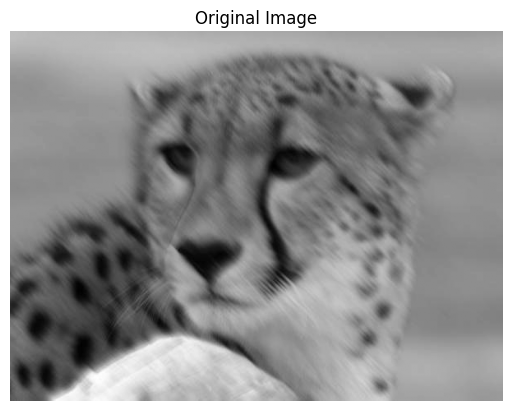

In [18]:
img = cv2.imread('/content/motion-blur.gif', 0)

plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')
plt.show()

In [19]:
F = np.fft.fftshift(np.fft.fft2(img))

M, N = img.shape

u, v = np.meshgrid(
    np.arange(N) - N//2,
    np.arange(M) - M//2
)

D = np.sqrt(u**2 + v**2)

In [31]:
LPF = D < 20
HPF = D >= 20

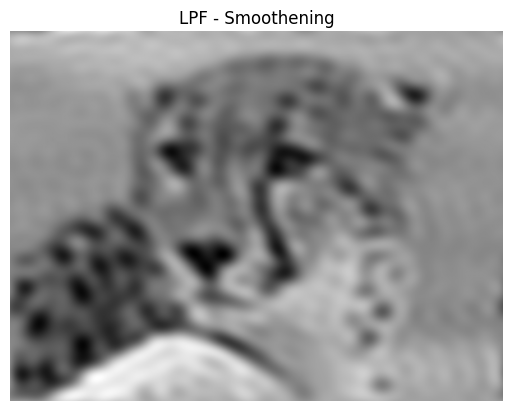

In [32]:
smooth = np.abs(
    np.fft.ifft2(
        np.fft.ifftshift(F * LPF)
    )
)

plt.imshow(smooth, cmap='gray')
plt.title('LPF - Smoothening')
plt.axis('off')
plt.show()

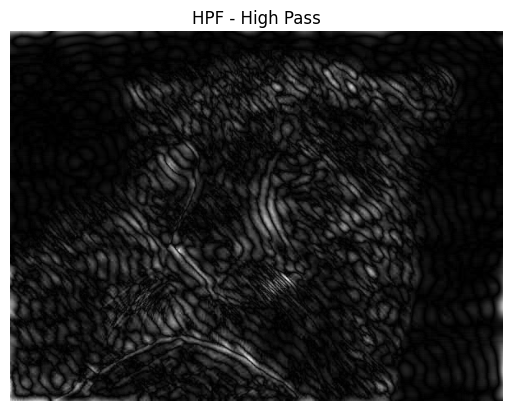

In [33]:
high_pass = np.abs(
    np.fft.ifft2(
        np.fft.ifftshift(F * HPF)
    )
)

plt.imshow(high_pass, cmap='gray')
plt.title('HPF - High Pass')
plt.axis('off')
plt.show()

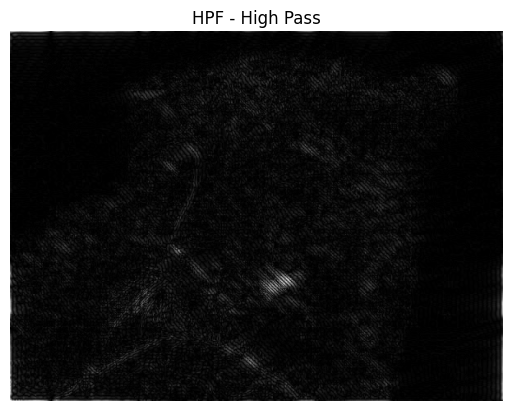

In [23]:
high_pass = np.abs(
    np.fft.ifft2(
        np.fft.ifftshift(F * HPF)
    )
)

plt.imshow(high_pass, cmap='gray')
plt.title('HPF - High Pass')
plt.axis('off')
plt.show()

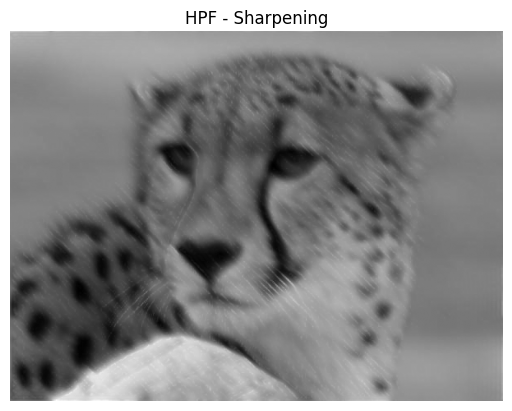

In [24]:
sharp = np.clip(
    img.astype(float) + high_pass,
    0, 255
)

plt.imshow(sharp, cmap='gray')
plt.title('HPF - Sharpening')
plt.axis('off')
plt.show()

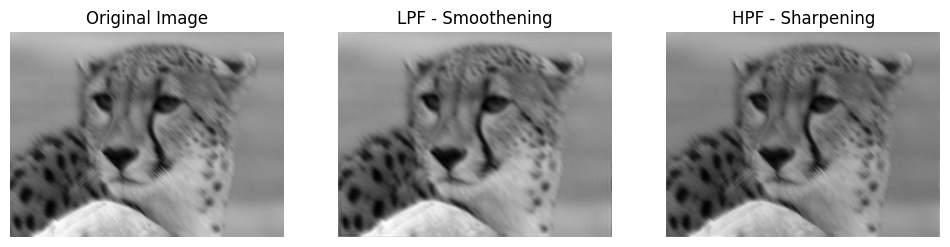

In [27]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(smooth, cmap='gray')
plt.title('LPF - Smoothening')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(sharp, cmap='gray')
plt.title('HPF - Sharpening')
plt.axis('off')

plt.show()